# Predicting Olympic Medals

## 1. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

## 2. Load the data

In [2]:
teams = pd.read_csv("teams.csv")
teams.head()

,team,country,year,events,athletes,age,height,weight,medals,prev_medals,prev_3_medals
0,AFG,Afghanistan,1964,8,8,22.0,161.0,64.2,0,0.0,0.0
1,AFG,Afghanistan,1968,5,5,23.2,170.2,70.0,0,0.0,0.0
2,AFG,Afghanistan,1972,8,8,29.0,168.3,63.8,0,0.0,0.0
3,AFG,Afghanistan,1980,11,11,23.6,168.4,63.2,0,0.0,0.0
4,AFG,Afghanistan,2004,5,5,18.6,170.8,64.8,0,0.0,0.0


In [3]:
teams = teams[["team", "country", "year", "athletes", "prev_medals", "medals"]]
teams.head()

,team,country,year,athletes,prev_medals,medals
0,AFG,Afghanistan,1964,8,0.0,0
1,AFG,Afghanistan,1968,5,0.0,0
2,AFG,Afghanistan,1972,8,0.0,0
3,AFG,Afghanistan,1980,11,0.0,0
4,AFG,Afghanistan,2004,5,0.0,0


## 3. Look at the data

In [4]:
teams.corr(numeric_only=True)["medals"]

year          -0.021603
athletes       0.840817
prev_medals    0.920048
medals         1.000000
Name: medals, dtype: float64

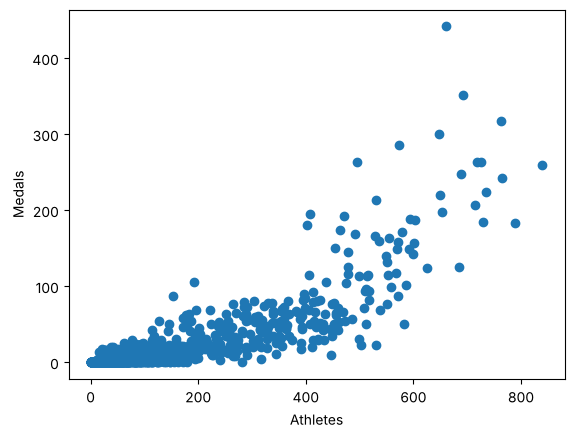

In [5]:
plt.scatter(teams["athletes"], teams["medals"])
plt.xlabel("Athletes")
plt.ylabel("Medals")
plt.show()

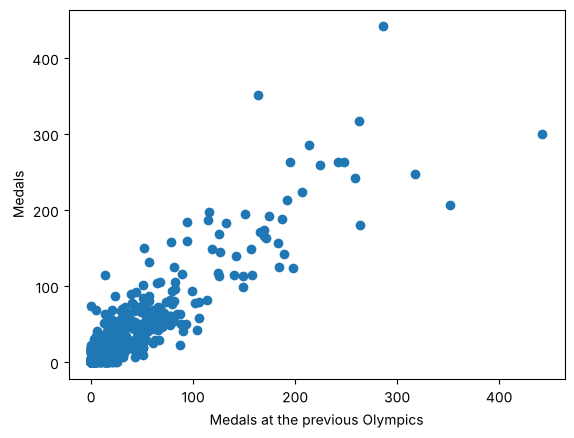

In [6]:
plt.scatter(teams["prev_medals"], teams["medals"])
plt.xlabel("Medals at the previous Olympics")
plt.ylabel("Medals")
plt.show()

## 4. Clean the data

In [7]:
print("Rows before:", len(teams))
teams = teams.dropna()
print("Rows after:", len(teams))

Rows before: 2144
Rows after: 2014


## 5. Split the data

In [8]:
train = teams[teams["year"] < 2012]
test = teams[teams["year"] >= 2012].copy()

print("Train rows:", len(train))
print("Test rows:", len(test))

Train rows: 1609
Test rows: 405


## 6. Train the model

In [9]:
features = ["athletes", "prev_medals"]

model = LinearRegression()
model.fit(train[features], train["medals"])

print("Weights:", model.coef_)
print("Bias:", model.intercept_)

Weights: [0.07170379 0.75062549]
Bias: -2.142069464116142


## 7. Make predictions

In [10]:
predictions = model.predict(test[features])

test["predictions"] = predictions
test.loc[test["predictions"] < 0, "predictions"] = 0
test["predictions"] = test["predictions"].round()

test[["country", "year", "medals", "predictions"]].head(10)

,country,year,medals,predictions
6,Afghanistan,2012,1,0.0
7,Afghanistan,2016,0,0.0
24,Albania,2012,0,0.0
25,Albania,2016,0,0.0
37,Algeria,2012,1,2.0
38,Algeria,2016,2,4.0
48,Andorra,2012,0,0.0
49,Andorra,2016,0,0.0
57,Angola,2012,0,0.0
58,Angola,2016,0,0.0


## 8. Check the error

In [11]:
mae = mean_absolute_error(test["medals"], test["predictions"])
print("Average error:", round(mae, 2), "medals")

Average error: 3.3 medals


## 9. Look at some countries

In [12]:
test[test["team"] == "USA"][["country", "year", "medals", "predictions"]]

,country,year,medals,predictions
2053,United States,2012,248,285.0
2054,United States,2016,264,236.0


In [13]:
test[test["team"] == "IND"][["country", "year", "medals", "predictions"]]

,country,year,medals,predictions
907,India,2012,6,7.0
908,India,2016,2,12.0


## 10. Try your own numbers

In [14]:
new_country = pd.DataFrame({"athletes": [100], "prev_medals": [10]})

guess = model.predict(new_country)
print("Predicted medals:", round(guess[0]))

Predicted medals: 13
